# MedVision Smart — Segmentation biomédicale intelligente
## Étape 1 · Notebook 02 : vérification du découpage, métriques et baselines (Otsu, CNN simple)

**Équipe :** Abderrahman Ghazouani · Hiba Hamrani · Anas Latifi — *notebook réalisé par Hiba Hamrani*

---

### Rôle de ce notebook

Le notebook 01 a préparé les données et produit le découpage officiel `splits.csv`. Ce notebook :

1. **vérifie** que ce découpage ne contient pas de fuite de données (quasi-doublons) ;
2. définit les **métriques communes** (Dice, IoU, mAP, rappel, précision) utilisées par toute l'équipe ;
3. construit, règle et évalue les **deux baselines** de la comparaison :
   - le **seuillage d'Otsu** (sans apprentissage) ;
   - un **CNN encodeur-décodeur simple** (sans skip connections).

Les baselines servent de **points de référence** : U-Net et U-Net++ (notebook 03) devront faire nettement mieux pour justifier leur complexité.

### Règle du protocole

Tous les réglages et toutes les évaluations de ce notebook se font sur la **validation**. Le **test** n'est utilisé qu'**une seule fois**, à la fin, dans le notebook 04, pour les 4 modèles en même temps.

### Fichiers utilisés et produits

| Fichier | Rôle |
|---|---|
| `splits.csv` | découpage train / val / test (notebook 01) |
| `utils.py` | lecture des images, `redimensionner()`, `metriques()` (partagés par l'équipe) |
| `otsu_baseline.py` | fonction d'Otsu réglable et réglage retenu |
| `reglage_cnn_simple.py` | script des 4 entraînements du CNN (lancé sur GPU) |
| `outputs/*.csv`, `outputs/*.png` | résultats et figures pour le rapport |

---
## 0. Préparation

- On importe les bibliothèques et les **fonctions partagées** de `utils.py` et `otsu_baseline.py`, pour que tout le monde lise les images et calcule les scores **exactement de la même façon**.
- On fixe la **graine aléatoire** (`SEED = 42`) pour que les résultats soient reproductibles.
- On charge les trois partitions depuis `splits.csv`. **On ne refait jamais le découpage** : c'est ce qui garantit que les 4 modèles sont comparés sur les mêmes images.
- `TAILLE = 256` : toutes les images sont redimensionnées en 256 × 256, comme pour U-Net et U-Net++.

In [1]:
import os, random, time, itertools
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
from tqdm import tqdm

from utils import lire_image, lire_masque, charger_split, redimensionner, metriques
from otsu_baseline import otsu_parametre, MEILLEUR_REGLAGE

# --- Reproductibilité ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)
TAILLE = 256

# --- Partitions officielles (notebook 01) ---
train_df = charger_split("train")
val_df   = charger_split("val")
test_df  = charger_split("test")

print("train :", len(train_df), "| val :", len(val_df), "| test :", len(test_df))
print("GPU disponible :", torch.cuda.is_available())

train : 537 | val : 114 | test : 111
GPU disponible : False


**Résultat attendu :** `train : 537 | val : 114 | test : 111` (762 images après le nettoyage du notebook 01).

---
## 1. Vérification du découpage : les quasi-doublons

### Le problème

Pour mesurer honnêtement un modèle, on le teste sur des images qu'il n'a **jamais vues**. Si une même échographie se trouve à la fois dans le train et dans la validation (ou le test), le modèle a déjà « vu la réponse » et son score est **artificiellement gonflé** : c'est une **fuite de données**.

Le notebook 01 supprime les doublons **exacts** avec un hash MD5 (images identiques au pixel près). Mais BUSI contient aussi des **quasi-doublons** : la même échographie enregistrée plusieurs fois avec une petite différence (redimensionnement, compression, léger recadrage). Pour le MD5, ce sont des images totalement différentes.

### La méthode

1. **Hash perceptuel (`phash`)** : une empreinte de 64 bits qui résume l'**apparence** de l'image. Deux images visuellement proches ont des empreintes proches.
2. **Distance de Hamming** : le nombre de bits différents entre deux empreintes (0 = images visuellement identiques).
3. **Corrélation des pixels** (images réduites en 128 × 128) : un second indice pour confirmer, entre 0 (sans rapport) et 1 (identiques).

### Cellule 1.1 : empreintes et paires très proches

On calcule une empreinte par image, puis la distance entre **toutes les paires** d'images (762 × 762), et on garde les paires de distance ≤ 6. Une paire est une **fuite** si ses deux images sont dans des partitions différentes.

In [2]:
import imagehash
from PIL import Image

tout_df = charger_split()   # toutes les images, toutes partitions confondues

# 1. Une empreinte perceptuelle par image
empreintes = [imagehash.phash(Image.open(p).convert("L"))
              for p in tqdm(tout_df["image_path"], desc="Calcul des phash")]

# 2. Chaque empreinte -> tableau de 64 bits (0/1)
bits = np.array([e.hash.flatten() for e in empreintes], dtype=np.uint8)

# 3. Distance de Hamming entre toutes les paires d'images
distances = (bits[:, None, :] != bits[None, :, :]).sum(axis=2)

# 4. Paires très proches (chaque paire comptée une fois)
SEUIL = 6
i, j = np.where(np.triu(distances <= SEUIL, k=1))

paires = pd.DataFrame({
    "image_1": tout_df.loc[i, "id"].values, "split_1": tout_df.loc[i, "split"].values,
    "image_2": tout_df.loc[j, "id"].values, "split_2": tout_df.loc[j, "split"].values,
    "distance": distances[i, j],
}).sort_values("distance")
paires["fuite"] = paires["split_1"] != paires["split_2"]

print(f"Paires presque identiques (distance <= {SEUIL}) : {len(paires)}")
print(f"Dont à cheval entre deux partitions (fuite) : {paires['fuite'].sum()}")

Calcul des phash: 100%|██████████| 762/762 [00:13<00:00, 57.73it/s]


Paires presque identiques (distance <= 6) : 198
Dont à cheval entre deux partitions (fuite) : 0


### Cellule 1.2 : vérification visuelle

La distance phash seule peut se tromper : toutes les échographies se ressemblent un peu (fond noir, texture granuleuse). On ajoute la **corrélation des pixels** et on **regarde les paires** pour savoir lesquelles sont de vraies copies.

La fonction `afficher_paires` affiche deux images côte à côte avec leur partition, leur distance et leur corrélation.

Nombre de paires par distance :
distance
0    40
2    87
4    47
6    24
Name: count, dtype: int64


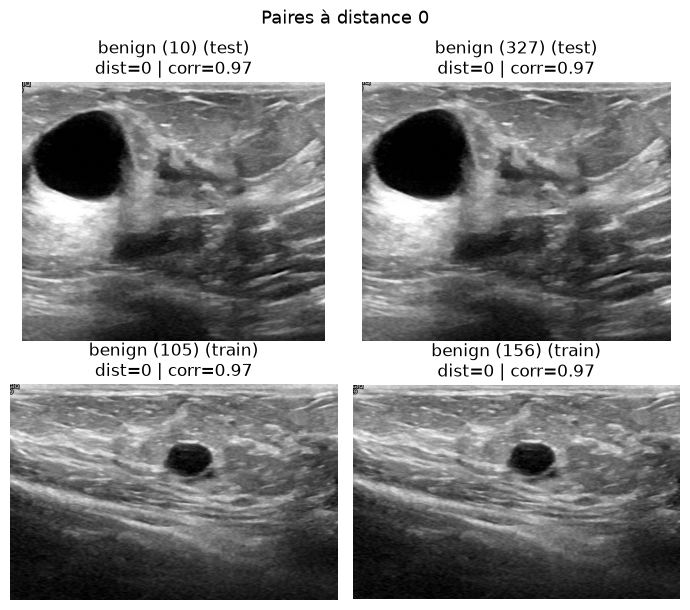

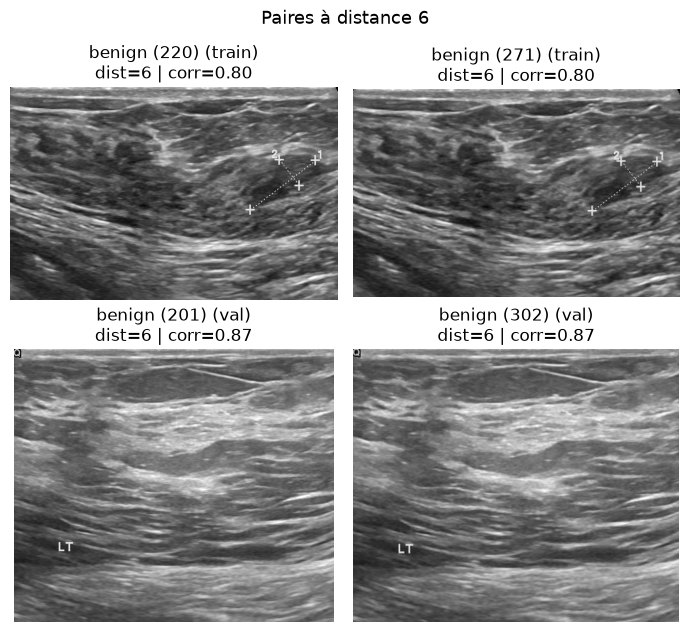

Fuites (distance <= 6) : aucune paire ✅


In [3]:
print("Nombre de paires par distance :")
print(paires["distance"].value_counts().sort_index())

chemins = tout_df.set_index("id")["image_path"]

def petite_image(img_id):
    # Image réduite à 128x128 pour comparer des images de tailles différentes
    return cv2.resize(lire_image(chemins[img_id]), (128, 128)).astype(np.float32).ravel()

paires["correlation"] = [np.corrcoef(petite_image(a), petite_image(b))[0, 1]
                         for a, b in zip(paires["image_1"], paires["image_2"])]

def afficher_paires(sous, titre):
    if len(sous) == 0:
        print(f"{titre} : aucune paire ✅")
        return
    fig, axes = plt.subplots(len(sous), 2, figsize=(7, 3.2 * len(sous)), squeeze=False)
    fig.suptitle(titre, fontsize=13)
    for k, (_, p) in enumerate(sous.iterrows()):
        for c, (img_id, split) in enumerate([(p["image_1"], p["split_1"]),
                                             (p["image_2"], p["split_2"])]):
            axes[k, c].imshow(lire_image(chemins[img_id]), cmap="gray")
            axes[k, c].set_title(f"{img_id} ({split})\ndist={p['distance']} | corr={p['correlation']:.2f}")
            axes[k, c].axis("off")
    plt.tight_layout()
    plt.show()

# Exemples de paires très proches (toutes partitions confondues)
afficher_paires(paires[paires["distance"] == 0].head(2), "Paires à distance 0")
afficher_paires(paires[paires["distance"] == 6].head(2), "Paires à distance 6")

# Fuites restantes (doit être vide avec le split corrigé)
fuites = paires[paires["fuite"]]
afficher_paires(fuites.head(3), "Fuites (distance <= 6)")

**Ce qu'on a observé :** à distance 0 comme à distance 6, les paires sont **la même échographie** (même tumeur, mêmes repères de mesure), même quand la corrélation est faible (jusqu'à 0,55). Une copie légèrement **décalée ou recadrée** fait chuter la corrélation, alors que le phash la reconnaît.

### Cellule 1.3 : paires plus éloignées (distance 7 à 12)

On cherche jusqu'où vont les copies. La fonction `construire_paires` fabrique le tableau des paires avec leur partition, leur classe et leur corrélation.

Nombre de paires par distance (7 à 12) :
distance
8      6
10    10
12    21
Name: count, dtype: int64


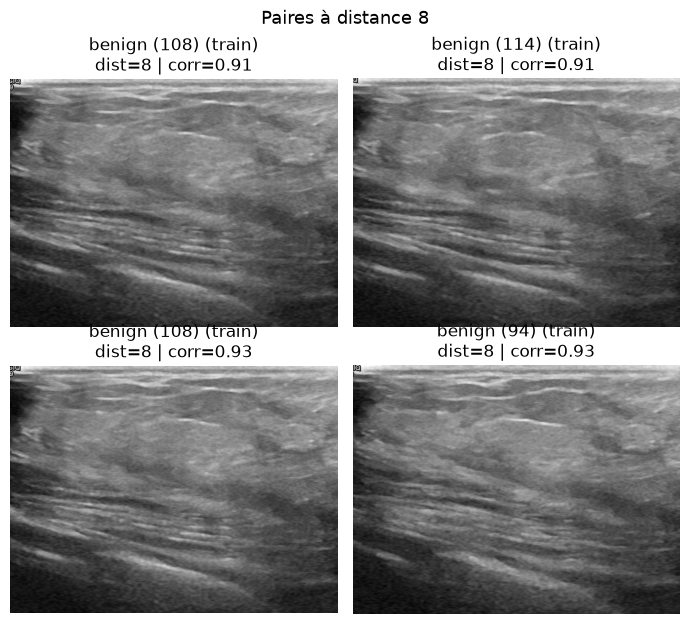

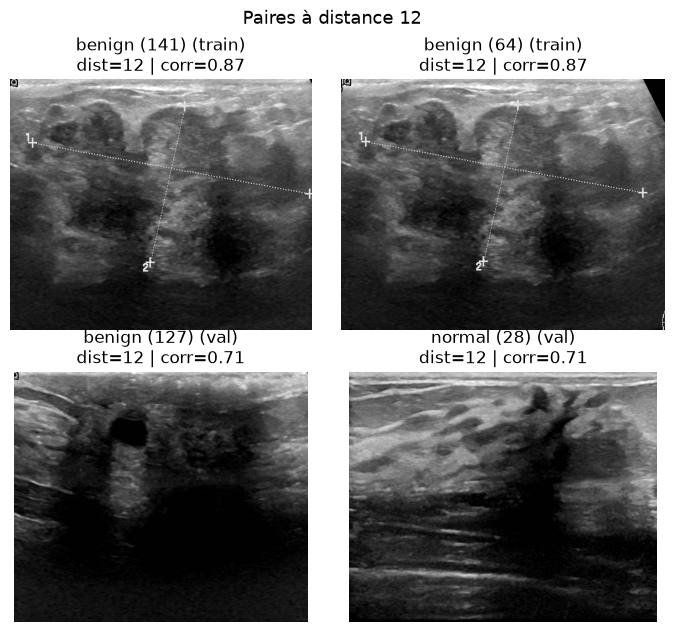

In [4]:
def construire_paires(i, j):
    p = pd.DataFrame({
        "image_1": tout_df.loc[i, "id"].values, "split_1": tout_df.loc[i, "split"].values,
        "classe_1": tout_df.loc[i, "classe"].values,
        "image_2": tout_df.loc[j, "id"].values, "split_2": tout_df.loc[j, "split"].values,
        "classe_2": tout_df.loc[j, "classe"].values,
        "distance": distances[i, j],
    })
    p["correlation"] = [np.corrcoef(petite_image(a), petite_image(b))[0, 1]
                        for a, b in zip(p["image_1"], p["image_2"])]
    return p.sort_values("distance")

i2, j2 = np.where(np.triu((distances > 6) & (distances <= 12), k=1))
plus_loin = construire_paires(i2, j2)

print("Nombre de paires par distance (7 à 12) :")
print(plus_loin["distance"].value_counts().sort_index())

for d in [8, 12]:
    afficher_paires(plus_loin[plus_loin["distance"] == d].head(2), f"Paires à distance {d}")

**Ce qu'on a observé :**
- à distance 8 à 12, on trouve encore des copies avec une **corrélation élevée** (≥ 0,85), par exemple `benign (141)` / `benign (64)` (mêmes repères de mesure) ;
- mais aussi des **faux positifs** : `benign (127)` / `normal (28)` sont deux images différentes (une tumeur d'un côté, aucune de l'autre), avec une corrélation de 0,71.

D'où la **règle retenue** :

> une paire est un doublon si **distance ≤ 6**, **ou** si **distance ≤ 12 et corrélation ≥ 0,85**.

### Cellule 1.4 : groupes de doublons et bilan des fuites

Une même image peut avoir plusieurs copies (A ~ B et B ~ C). On forme donc des **groupes** avec un graphe (composantes connexes). Un groupe est une **fuite** s'il est réparti sur plusieurs partitions. L'`assert` final arrête le notebook si une fuite réapparaît.

In [5]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

# 1. Paires candidates (distance <= 12) avec leur corrélation
i3, j3 = np.where(np.triu(distances <= 12, k=1))
candidates = construire_paires(i3, j3)

# 2. Règle retenue
regle = (candidates["distance"] <= 6) | (candidates["correlation"] >= 0.85)
vraies = candidates[regle]
print(f"Paires candidates : {len(candidates)} | doublons : {len(vraies)} "
      f"| faux positifs écartés : {len(candidates) - len(vraies)}")

# 3. Groupes : si A~B et B~C, alors A, B, C sont la même image
pos = {img_id: k for k, img_id in enumerate(tout_df["id"])}
a = vraies["image_1"].map(pos).values
b = vraies["image_2"].map(pos).values
n = len(tout_df)
graphe = csr_matrix((np.ones(len(a)), (a, b)), shape=(n, n))
_, tout_df["groupe"] = connected_components(graphe, directed=False)

taille_groupe = tout_df.groupby("groupe")["id"].transform("size")
par_groupe = tout_df[taille_groupe > 1].groupby("groupe").agg(
    images=("id", lambda s: ", ".join(s)),
    splits=("split", lambda s: ", ".join(sorted(set(s)))),
    nb_splits=("split", "nunique"),
    nb_classes=("classe", "nunique"))

# 4. Bilan
fuites_groupes = par_groupe[par_groupe["nb_splits"] > 1]
print(f"\nImages ayant au moins un doublon : {(taille_groupe > 1).sum()}")
print(f"Groupes de doublons : {len(par_groupe)}")
print(f"Groupes à cheval entre partitions (fuite) : {len(fuites_groupes)}")
print(f"Groupes avec classes contradictoires : {(par_groupe['nb_classes'] > 1).sum()}")

# 5. Sauvegarde pour l'équipe
tout_df[taille_groupe > 1][["id", "classe", "split", "groupe"]].sort_values("groupe") \
    .to_csv(f"{OUT_DIR}/groupes_quasi_doublons.csv", index=False)

assert len(fuites_groupes) == 0, "Fuite détectée : un groupe de doublons est réparti sur plusieurs partitions !"
print("\n✅ Aucune fuite : chaque groupe de copies est entièrement dans une seule partition.")

Paires candidates : 235 | doublons : 214 | faux positifs écartés : 21

Images ayant au moins un doublon : 308
Groupes de doublons : 136
Groupes à cheval entre partitions (fuite) : 0
Groupes avec classes contradictoires : 0

✅ Aucune fuite : chaque groupe de copies est entièrement dans une seule partition.


### Bilan de la vérification

| Étape | Résultat |
|---|---|
| 1er contrôle (premier `splits.csv`, règle phash + corrélation ≥ 0,85) | **64 groupes en fuite**, dont certains entre train et test → split régénéré (notebook 01) |
| 2e contrôle (règle corrigée, distance ≤ 6 toujours retenue) | **4 groupes en fuite**, tous entre train et val (le test était déjà propre) → corrigés |
| Contrôle actuel | **0 fuite**, 0 classe contradictoire ✅ |

- **308 images** ont au moins une copie, réparties en **136 groupes** : plus d'un tiers de BUSI est concerné.
- Chaque groupe est maintenant entièrement dans **une seule** partition : les scores mesurés sur la validation et sur le test sont fiables.
- **Limite :** BUSI ne fournit pas d'identifiant patient. Deux images *différentes* d'une même patiente peuvent encore se trouver dans des partitions différentes.

---
## 2. Les métriques communes

Les métriques comparent le masque **prédit** au masque **réel** (tracé par le radiologue). Pour chaque pixel :

| | Le modèle dit « tumeur » | Le modèle dit « fond » |
|---|---|---|
| **Vraiment tumeur** | **VP** (vrai positif) | **FN** (faux négatif) : tumeur ratée |
| **Vraiment fond** | **FP** (faux positif) : fausse alerte | VN (vrai négatif) |

| Métrique | Formule | Ce qu'elle mesure |
|---|---|---|
| **Dice** | 2·VP / (2·VP + FP + FN) | superposition des deux masques (métrique principale) |
| **IoU** | VP / (VP + FP + FN) | intersection / union, plus sévère que le Dice |
| **mAP** | proportion des seuils d'IoU 0,50 ; 0,55 ; … ; 0,95 atteints | précision du contour (très exigeante) |
| **Rappel** | VP / (VP + FN) | part de la tumeur retrouvée (rater une tumeur est grave en médecine) |
| **Précision** | VP / (VP + FP) | part de la détection qui est vraiment de la tumeur |

**Images normales (sans tumeur) :** le calcul donnerait 0/0. On décide : Dice = IoU = mAP = **1** si le modèle ne prédit rien, **0** s'il signale une tumeur ; le rappel n'a pas de sens (**NaN**, ignoré dans les moyennes).

La fonction `metriques()` est dans `utils.py`, pour que **toute l'équipe** calcule les scores exactement de la même façon. On la **teste** sur des masques fabriqués à la main dont on connaît la bonne réponse.

In [6]:
vrai_test = np.zeros((10, 10), dtype=np.uint8)
vrai_test[2:6, 2:6] = 1                      # tumeur carrée de 16 pixels
moitie_test = np.zeros_like(vrai_test)
moitie_test[2:6, 2:4] = 1                    # moitié gauche trouvée
vide_test = np.zeros_like(vrai_test)

cas = {
    "Prédiction parfaite":          metriques(vrai_test, vrai_test),
    "Moitié trouvée":               metriques(moitie_test, vrai_test),
    "Rien trouvé":                  metriques(vide_test, vrai_test),
    "Image normale, rien prédit":   metriques(vide_test, vide_test),
    "Image normale, fausse alerte": metriques(moitie_test, vide_test),
}
display(pd.DataFrame(cas).T.astype(float).round(3))

# Vérifications automatiques
assert np.isclose(cas["Moitié trouvée"]["dice"], 2 / 3)
assert np.isclose(cas["Moitié trouvée"]["iou"], 0.5) and np.isclose(cas["Moitié trouvée"]["map"], 0.1)
assert cas["Image normale, rien prédit"]["dice"] == 1 and cas["Image normale, fausse alerte"]["dice"] == 0
print("✅ Les métriques donnent les résultats attendus.")

,dice,iou,map,rappel,precision
Prédiction parfaite,1.000,1.0,1.0,1.0,1.0
Moitié trouvée,0.667,0.5,0.1,0.5,1.0
Rien trouvé,0.000,0.0,0.0,0.0,0.0
"Image normale, rien prédit",1.000,1.0,1.0,NaN,1.0
"Image normale, fausse alerte",0.000,0.0,0.0,NaN,0.0


✅ Les métriques donnent les résultats attendus.


**Lecture :** dans « moitié trouvée », la précision vaut 1 (tout ce qui est détecté est de la tumeur) mais le rappel vaut 0,5 (la moitié de la tumeur est ratée). Le Dice vaut 0,67, mais le mAP seulement **0,1** : seul le seuil d'IoU 0,50 est atteint. Le mAP récompense uniquement les contours **très précis**. C'est pour cela qu'on regarde **plusieurs métriques**.

---
## 3. Baseline 1 : le seuillage d'Otsu

### Principe

Otsu est une méthode **sans apprentissage** : elle choisit automatiquement le seuil de gris qui sépare le mieux les pixels sombres des pixels clairs. En échographie, les tumeurs sont souvent **sombres** (hypoéchogènes), donc on garde les pixels sous le seuil.

Pipeline (fonction `otsu_parametre` de `otsu_baseline.py`) :
1. **Flou gaussien** : lisse le grain de l'échographie ;
2. **Seuil d'Otsu inversé** : zones sombres = 1, zones claires = 0 ;
3. **Nettoyage** (ouverture morphologique) : efface les petits points isolés ;
4. **Choix d'une zone** : toutes les zones, la plus grande, ou la plus grande **qui ne touche pas le bord**.

### Cellule 3.1 : Otsu naïf vs Otsu sans bord, sur quelques exemples

- **Otsu naïf** : garde la plus grande zone sombre.
- **Otsu sans bord** : ignore les zones dont le rectangle englobant touche un bord de l'image (ombre en bas, bords noirs de l'appareil).

On utilise des images de **validation** (avec tumeur).

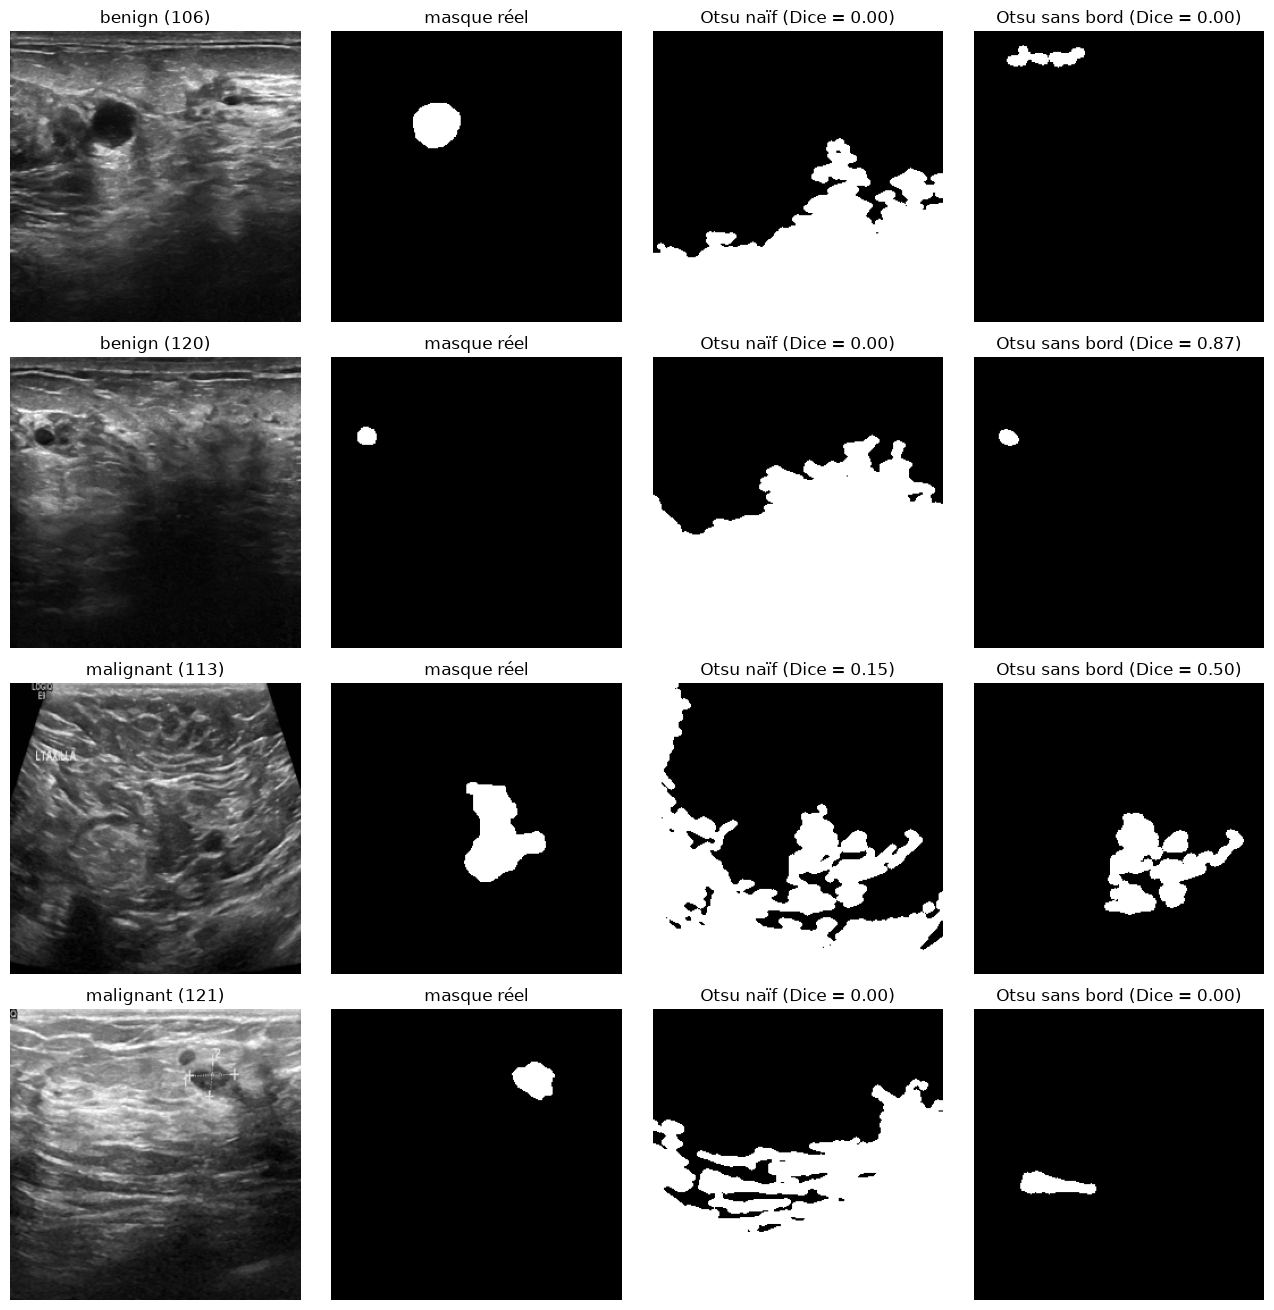

In [7]:
exemples = val_df[val_df["classe"] != "normal"].groupby("classe").head(2)

fig, axes = plt.subplots(len(exemples), 4, figsize=(13, 3.3 * len(exemples)))
for k, (_, ligne) in enumerate(exemples.iterrows()):
    img, verite = redimensionner(lire_image(ligne["image_path"]), lire_masque(ligne["mask_paths"]), TAILLE)
    p_naif = otsu_parametre(img, flou=5, nettoyage=7, zone="plus_grande")
    p_bord = otsu_parametre(img, **MEILLEUR_REGLAGE)
    axes[k, 0].imshow(img, cmap="gray");    axes[k, 0].set_title(ligne["id"])
    axes[k, 1].imshow(verite, cmap="gray"); axes[k, 1].set_title("masque réel")
    axes[k, 2].imshow(p_naif, cmap="gray")
    axes[k, 2].set_title(f"Otsu naïf (Dice = {metriques(p_naif, verite)['dice']:.2f})")
    axes[k, 3].imshow(p_bord, cmap="gray")
    axes[k, 3].set_title(f"Otsu sans bord (Dice = {metriques(p_bord, verite)['dice']:.2f})")
    for ax in axes[k]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/otsu_naif_vs_sans_bord.png", dpi=150)
plt.show()

**Ce qu'on observe :** l'Otsu naïf sélectionne presque toujours **le bas de l'image**. En échographie, les ultrasons s'atténuent en profondeur : le bas est sombre même sans tumeur, et c'est la plus grande zone sombre. En excluant les zones qui touchent le bord, Otsu trouve parfois la tumeur, mais il se trompe encore quand une autre zone sombre est plus grande qu'elle.

### Cellule 3.2 : réglage des hyperparamètres sur la validation

On teste **27 combinaisons** (3 tailles de flou × 3 tailles de nettoyage × 3 choix de zone) sur les images de **validation**, et on garde celle qui a le meilleur Dice moyen.

In [8]:
# Images de validation chargées une seule fois
val_images = [redimensionner(lire_image(l["image_path"]), lire_masque(l["mask_paths"]), TAILLE)
              for _, l in val_df.iterrows()]

grille = list(itertools.product([3, 5, 9], [0, 5, 9], ["toutes", "plus_grande", "sans_bord"]))
resume_otsu = []
for flou, nettoyage, zone in tqdm(grille, desc="Réglage d'Otsu"):
    s = pd.DataFrame([metriques(otsu_parametre(img, flou, nettoyage, zone), verite)
                      for img, verite in val_images])
    resume_otsu.append({"flou": flou, "nettoyage": nettoyage, "zone": zone,
                        "dice": s["dice"].mean(), "iou": s["iou"].mean(), "map": s["map"].mean(),
                        "rappel": s["rappel"].mean(), "precision": s["precision"].mean()})

resume_otsu = pd.DataFrame(resume_otsu).sort_values("dice", ascending=False).reset_index(drop=True)
resume_otsu.to_csv(f"{OUT_DIR}/reglage_otsu_val.csv", index=False)

print("=== Les 5 meilleurs réglages (validation) ===")
display(resume_otsu.head(5).round(3))
print("=== Les 3 moins bons ===")
display(resume_otsu.tail(3).round(3))

meilleur = resume_otsu.iloc[0]
print(f"Meilleur réglage : flou {meilleur['flou']}, nettoyage {meilleur['nettoyage']}, "
      f"zone '{meilleur['zone']}' -> Dice val {meilleur['dice']:.3f}")
print("Réglage enregistré dans otsu_baseline.py :", MEILLEUR_REGLAGE)

Réglage d'Otsu: 100%|██████████| 27/27 [00:06<00:00,  4.15it/s]

=== Les 5 meilleurs réglages (validation) ===


,flou,nettoyage,zone,dice,iou,map,rappel,precision
0,3,9,sans_bord,0.201,0.167,0.099,0.213,0.329
1,5,9,sans_bord,0.194,0.160,0.094,0.214,0.313
2,9,9,sans_bord,0.194,0.163,0.102,0.197,0.301
3,3,5,sans_bord,0.164,0.137,0.084,0.188,0.254
4,5,5,sans_bord,0.159,0.133,0.083,0.180,0.244


=== Les 3 moins bons ===


,flou,nettoyage,zone,dice,iou,map,rappel,precision
24,3,9,plus_grande,0.128,0.085,0.010,0.432,0.091
25,5,0,sans_bord,0.113,0.095,0.058,0.130,0.203
26,3,0,sans_bord,0.113,0.095,0.058,0.130,0.193


Meilleur réglage : flou 3, nettoyage 9, zone 'sans_bord' -> Dice val 0.201
Réglage enregistré dans otsu_baseline.py : {'flou': 3, 'nettoyage': 9, 'zone': 'sans_bord'}


**Interprétation du réglage :**
- **Meilleur réglage : flou 3, nettoyage 9, zone « sans bord » → Dice val 0,201.**
- **Exclure les zones qui touchent le bord** est le réglage le plus important : les 5 meilleures combinaisons l'utilisent toutes.
- **Un nettoyage fort aide** (9 > 5 > aucun) : effacer les petites taches évite de choisir une zone de bruit.
- **La taille du flou compte peu** (0,194 à 0,201).
- Le meilleur nettoyage (9) est la plus grande valeur testée : un nettoyage plus fort apporterait peut-être un léger gain, mais la baseline reste volontairement simple.

### Cellule 3.3 : résultats détaillés d'Otsu (réglage retenu) sur la validation

On applique le réglage retenu à chaque image de validation, on chronomètre le calcul, et on enregistre les résultats image par image pour le tableau comparatif et l'analyse d'erreurs.

In [9]:
lignes = []
for (img, verite), (_, l) in zip(val_images, val_df.iterrows()):
    debut = time.perf_counter()
    pred = otsu_parametre(img, **MEILLEUR_REGLAGE)
    duree_ms = (time.perf_counter() - debut) * 1000
    lignes.append({"modele": "Otsu", "id": l["id"], "classe": l["classe"],
                   **metriques(pred, verite), "temps_ms": duree_ms})

res_otsu_val = pd.DataFrame(lignes)
res_otsu_val.to_csv(f"{OUT_DIR}/resultats_otsu_val.csv", index=False)

cols = ["dice", "iou", "map", "rappel", "precision", "temps_ms"]
print("=== Otsu réglé : moyenne sur la validation ===")
display(res_otsu_val[cols].mean().round(3).to_frame("Otsu").T)
print("=== Dice par classe ===")
display(res_otsu_val.groupby("classe")["dice"].mean().round(3).to_frame("Otsu").T)

=== Otsu réglé : moyenne sur la validation ===


,dice,iou,map,rappel,precision,temps_ms
Otsu,0.201,0.167,0.099,0.213,0.329,1.557


=== Dice par classe ===


classe,benign,malignant,normal
Otsu,0.328,0.078,0.045


**Interprétation :**

| | Dice | Lecture |
|---|---|---|
| Moyenne | **0,201** (mAP 0,099) | faible, presque jamais de contour précis |
| Bénigne | 0,328 | réussit parfois : tumeurs rondes, sombres, bien délimitées |
| Maligne | 0,078 | échoue presque toujours : tumeurs hétérogènes, contours irréguliers |
| Normale | 0,045 | signale une « tumeur » sur presque toutes les images saines |

- **Temps : ~1,5 ms par image**, c'est son seul vrai atout.
- **Conclusion :** Otsu ne « reconnaît » pas une tumeur, il ne voit que des zones sombres. Même bien réglé, il plafonne vers un Dice de **0,20**. C'est le niveau minimum que les modèles avec apprentissage doivent largement dépasser.

---
## 4. Baseline 2 : le CNN encodeur-décodeur simple

### Principe

Au lieu de règles écrites à la main, le réseau **apprend** à reconnaître les tumeurs à partir des images du train.

- L'**encodeur** réduit l'image étape par étape (256 → 128 → 64 → 32 → 16) et apprend **ce qu'il y a** dans l'image (convolutions 3×3 + BatchNorm + ReLU, puis MaxPool).
- Le **décodeur** l'agrandit de nouveau (16 → … → 256) avec des convolutions transposées et produit un **score « tumeur » par pixel**.

```
Encodeur : 256×256 (16 filtres) → 128 (32) → 64 (64) → 32 (128)
Centre   : 16×16 (256 filtres)
Décodeur : 32 (128) → 64 (64) → 128 (32) → 256×256 (16) → masque (1 canal)
```

**Différence avec U-Net :** il n'y a **pas de skip connections**. Le décodeur ne reçoit que l'image compressée, donc les détails fins perdus pendant la compression (contours précis) ne lui reviennent jamais. On s'attend à des contours moins précis. C'est ce que la comparaison avec U-Net doit montrer.

### Cellule 4.1 : vérification de l'architecture

Le modèle est défini dans `reglage_cnn_simple.py` (classe `CNNSimple`). On compte ses paramètres et on vérifie qu'une image 256 × 256 ressort bien en 256 × 256.

In [10]:
from reglage_cnn_simple import CNNSimple

modele_test = CNNSimple()
nb_params = sum(p.numel() for p in modele_test.parameters())
print(f"Nombre de paramètres : {nb_params:,}")

with torch.no_grad():
    sortie = modele_test(torch.zeros(2, 1, TAILLE, TAILLE))
print("Entrée : (2, 1, 256, 256) -> Sortie :", tuple(sortie.shape))

Nombre de paramètres : 1,747,921
Entrée : (2, 1, 256, 256) -> Sortie : (2, 1, 256, 256)


**Résultat attendu :** 1 747 921 paramètres, et une sortie de même taille que l'entrée.

### Le protocole d'entraînement et de réglage

L'entraînement est fait par le script **`reglage_cnn_simple.py`**, lancé sur le GPU (environ 1 h par entraînement sur CPU, quelques minutes sur GPU) :

```
python reglage_cnn_simple.py
```

| Élément | Choix |
|---|---|
| Données | train (537 images) en 256 × 256, pixels entre 0 et 1, **miroir gauche-droite aléatoire** (augmentation) |
| Optimiseur | Adam, lots de 8 images |
| **Hyperparamètres réglés** | perte **BCE + Dice** vs **Dice seule** × learning rate **1e-3** vs **1e-4** → **4 entraînements** |
| Sélection | meilleur **Dice de validation** ; **early stopping** après 10 époques sans amélioration (max 40) |
| Évaluation | sur la **validation**, avec `metriques()` de `utils.py` + temps d'inférence |

**Pourquoi ces hyperparamètres ?**
- **Perte :** la **BCE** juge chaque pixel, mais le fond représente plus de 90 % des pixels, donc ignorer la tumeur coûte peu. La perte **Dice** juge la forme globale de la tumeur. On compare la combinaison des deux avec la Dice seule.
- **Learning rate :** un premier entraînement (lr = 1e-3) donnait un Dice de validation qui **oscillait fortement** d'une époque à l'autre (entre 0,40 et 0,62). Un learning rate plus petit (1e-4) pourrait stabiliser l'apprentissage.

### Cellule 4.2 : résultats des 4 configurations (validation)

In [11]:
chemin_resume = f"{OUT_DIR}/resume_reglage_cnn.csv"
if os.path.exists(chemin_resume):
    resume_cnn = pd.read_csv(chemin_resume)
    display(resume_cnn[["config", "dice", "iou", "map", "rappel", "precision",
                        "dice_benign", "dice_malignant", "dice_normal",
                        "meilleure_epoque", "nb_epoques", "temps_entrainement_min",
                        "temps_inference_ms"]].round(3))
    meilleure_config = resume_cnn.iloc[0]["config"]
    print(f"Meilleure configuration (Dice val) : {meilleure_config}")
else:
    print("⏳ Résultats pas encore disponibles : lancer `python reglage_cnn_simple.py` (GPU), "
          "puis récupérer le dossier outputs/.")

,config,dice,iou,map,rappel,precision,dice_benign,dice_malignant,dice_normal,meilleure_epoque,nb_epoques,temps_entrainement_min,temps_inference_ms
0,bce_dice_lr0.001,0.655,0.572,0.405,0.607,0.770,0.664,0.559,0.773,29,39,3.1,5.770
1,bce_dice_lr0.0001,0.585,0.497,0.317,0.678,0.642,0.614,0.592,0.500,28,38,3.8,4.281
2,dice_lr0.001,0.539,0.466,0.324,0.428,0.747,0.548,0.305,0.864,8,18,2.1,4.616
3,dice_lr0.0001,0.456,0.353,0.140,0.737,0.464,0.525,0.609,0.046,7,17,2.0,4.756


Meilleure configuration (Dice val) : bce_dice_lr0.001


### Cellule 4.3 : courbes d'apprentissage des 4 configurations

- **À gauche**, la perte de validation : si elle remonte pendant que la perte d'entraînement baisse, c'est du **surapprentissage**.
- **À droite**, le Dice de validation : on regarde le niveau atteint et la **stabilité** d'une époque à l'autre.

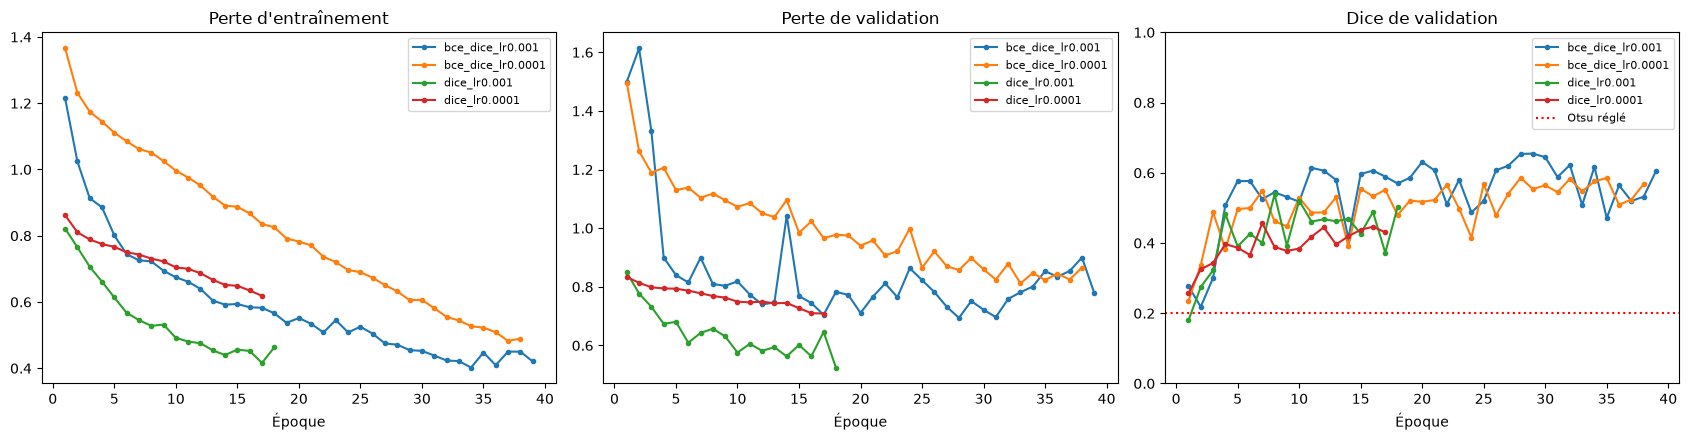

In [12]:
configs = ["bce_dice_lr0.001", "bce_dice_lr0.0001", "dice_lr0.001", "dice_lr0.0001"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
trouve = False
for cfg in configs:
    chemin = f"{OUT_DIR}/historique_cnn_{cfg}.csv"
    if not os.path.exists(chemin):
        continue
    trouve = True
    h = pd.read_csv(chemin)
    axes[0].plot(h["epoque"], h["perte_train"], "o-", markersize=3, label=cfg)
    axes[1].plot(h["epoque"], h["perte_val"], "o-", markersize=3, label=cfg)
    axes[2].plot(h["epoque"], h["dice_val"], "o-", markersize=3, label=cfg)

if trouve:
    axes[0].set_title("Perte d'entraînement")
    axes[1].set_title("Perte de validation")
    axes[2].set_title("Dice de validation")
    axes[2].axhline(res_otsu_val["dice"].mean(), color="red", linestyle=":", label="Otsu réglé")
    axes[2].set_ylim(0, 1)
    for ax in axes:
        ax.set_xlabel("Époque")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/courbes_cnn_simple_4_configs.png", dpi=150)
    plt.show()
else:
    plt.close(fig)
    print("⏳ Historiques pas encore disponibles.")

### Cellule 4.4 : exemples de prédictions du meilleur CNN (validation)

Cette cellule affiche des exemples de prédictions si les poids du modèle (`modeles/cnn_simple_bce_dice_lr0.001.pth`, entraîné sur GPU, non versionné sur GitHub car trop lourd) sont présents. Les comparaisons visuelles des 4 modèles, CNN simple compris, sont présentées dans le **notebook 04** (`outputs/04_meme_image_4_algos.png`, `outputs/04_pires_cas_U-Net.png`).

In [16]:
chemin_res = f"{OUT_DIR}/resultats_cnn_val.csv"
if os.path.exists(chemin_resume) and os.path.exists(chemin_res) \
        and os.path.exists(f"modeles/cnn_simple_{meilleure_config}.pth"):
    modele = CNNSimple()
    modele.load_state_dict(torch.load(f"modeles/cnn_simple_{meilleure_config}.pth", map_location="cpu"))
    modele.eval()

    res_cnn_val = pd.read_csv(chemin_res)
    res_cnn_val = res_cnn_val[res_cnn_val["modele"] == f"CNN simple ({meilleure_config})"]
    avec_tumeur = res_cnn_val[res_cnn_val["classe"] != "normal"].sort_values("dice")
    choix = pd.concat([avec_tumeur.tail(2), avec_tumeur.iloc[[len(avec_tumeur) // 2]],
                       avec_tumeur.head(2)])["id"]

    infos = val_df.set_index("id")
    fig, axes = plt.subplots(len(choix), 3, figsize=(10, 3.3 * len(choix)))
    for k, img_id in enumerate(choix):
        l = infos.loc[img_id]
        img, verite = redimensionner(lire_image(l["image_path"]), lire_masque(l["mask_paths"]), TAILLE)
        with torch.no_grad():
            x = torch.from_numpy(img.astype(np.float32) / 255.0)[None, None]
            pred = (torch.sigmoid(modele(x)) > 0.5).numpy()[0, 0].astype(np.uint8)
        p_otsu = otsu_parametre(img, **MEILLEUR_REGLAGE)
        axes[k, 0].imshow(img, cmap="gray"); axes[k, 0].set_title(img_id)
        for c, (p, nom) in enumerate([(p_otsu, "Otsu"), (pred, "CNN simple")], start=1):
            axes[k, c].imshow(img, cmap="gray")
            axes[k, c].contour(verite, colors="lime", linewidths=1.5)
            if p.any():
                axes[k, c].contour(p, colors="red", linewidths=1.5)
            axes[k, c].set_title(f"{nom} (Dice = {metriques(p, verite)['dice']:.2f})")
        for ax in axes[k]:
            ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/exemples_otsu_cnn_val.png", dpi=150)
    plt.show()
else:
    print("⏳ Modèle ou résultats du CNN pas encore disponibles.")

⏳ Modèle ou résultats du CNN pas encore disponibles.


**Interprétation des résultats du CNN :**

- **Meilleure configuration : perte BCE + Dice, learning rate 1e-3** → Dice val **0,655**, IoU 0,572, mAP 0,405, rappel 0,607, précision 0,770 (meilleure époque 29 sur 39).
- **BCE + Dice vs Dice seule :** la combinaison est meilleure avec les deux learning rates. Avec la Dice seule, l'apprentissage s'arrête très tôt (meilleure époque 7-8) et le modèle est déséquilibré : trop prudent avec lr 1e-3 (rappel 0,43), trop large avec lr 1e-4 (précision 0,46, fausses alertes sur presque toutes les images normales). Le terme BCE donne un signal pixel par pixel qui stabilise l'apprentissage.
- **lr 1e-3 vs 1e-4 :** avec 1e-4, la perte d'entraînement baisse beaucoup plus lentement : 40 époques ne suffisent pas à converger. L'hypothèse d'un Dice plus stable n'est que partiellement vérifiée : les oscillations diminuent un peu, mais à un niveau plus bas.
- **Surapprentissage :** pour la meilleure configuration, la perte de validation cesse de baisser vers l'époque 15-20 puis remonte, pendant que la perte d'entraînement continue de diminuer. L'early stopping (patience 10) retient le meilleur Dice de validation.
- **Attention :** les pertes de validation des configurations « Dice seule » ne sont pas comparables aux autres (pas de terme BCE). On compare les configurations sur le **Dice**.
- **Par classe :** le CNN reste plus faible sur les tumeurs **malignes** (0,559) que sur les bénignes (0,664) : leurs contours irréguliers sont difficiles à reconstruire sans skip connections.

---
## 5. Synthèse des baselines (validation)

On compare Otsu réglé et la meilleure configuration du CNN simple, sur les **mêmes images de validation**, avec les **mêmes métriques**.

In [14]:
tableaux = [res_otsu_val.assign(modele="Otsu (réglé)")]
if os.path.exists(chemin_res) and os.path.exists(chemin_resume):
    r = pd.read_csv(chemin_res)
    tableaux.append(r[r["modele"] == f"CNN simple ({meilleure_config})"]
                    .assign(modele=f"CNN simple ({meilleure_config})"))
tous_val = pd.concat(tableaux)

cols = ["dice", "iou", "map", "rappel", "precision", "temps_ms"]
print("=== Moyenne sur la validation ===")
display(tous_val.groupby("modele")[cols].mean().round(3))
print("=== Images avec tumeur seulement ===")
display(tous_val[tous_val["classe"] != "normal"].groupby("modele")[cols].mean().round(3))
print("=== Dice par classe ===")
display(tous_val.pivot_table(index="modele", columns="classe", values="dice").round(3))

=== Moyenne sur la validation ===


,dice,iou,map,rappel,precision,temps_ms
modele,,,,,,
CNN simple (bce_dice_lr0.001),0.655,0.572,0.405,0.607,0.770,5.771
Otsu (réglé),0.201,0.167,0.099,0.213,0.329,1.557


=== Images avec tumeur seulement ===


,dice,iou,map,rappel,precision,temps_ms
modele,,,,,,
CNN simple (bce_dice_lr0.001),0.627,0.525,0.317,0.607,0.770,5.665
Otsu (réglé),0.238,0.196,0.112,0.213,0.397,1.567


=== Dice par classe ===


classe,benign,malignant,normal
modele,,,
CNN simple (bce_dice_lr0.001),0.664,0.559,0.773
Otsu (réglé),0.328,0.078,0.045


### Conclusions

- **Vérification du découpage :** BUSI contient de nombreux quasi-doublons (308 images, 136 groupes) que le MD5 ne détecte pas. Après deux corrections du split, **aucun groupe n'est réparti sur plusieurs partitions**.
- **Otsu** (réglé sur 27 combinaisons) plafonne à un **Dice de 0,20** : sans apprentissage, il ne distingue pas une tumeur d'une autre zone sombre, et il signale une tumeur sur presque toutes les images normales.
- **CNN simple** (meilleure configuration : BCE + Dice, lr 1e-3) atteint un **Dice de 0,655** (mAP 0,405), soit **3,3 fois mieux qu'Otsu**. Il apprend à ne rien signaler sur les images normales (Dice 0,773 contre 0,045). Sans skip connections, les contours fins se perdent, en particulier pour les tumeurs malignes (0,559). *Remarque : le temps d'inférence du CNN (5,8 ms) a été mesuré sur GPU, celui d'Otsu (1,6 ms) sur CPU.*

### Ce qui est transmis aux notebooks suivants

| Élément | Utilisé par |
|---|---|
| `metriques()`, `redimensionner()` dans `utils.py` | notebooks 03 et 04 (mêmes scores pour les 4 modèles) |
| `otsu_baseline.py` (réglage retenu) | notebook 04 (évaluation finale sur le test) |
| `modeles/cnn_simple_<meilleure config>.pth` | notebook 04 |
| `outputs/resultats_*_val.csv`, figures | tableau comparatif et rapport |